# Finite-size trainability

Measure how gradient variance changes with width, depth and photon subtractions. Recompute the statistics from the stored initialization checkpoints.

## Setup

Locate the repository, import the analysis tools and enable inline plots. The statistics below come from the stored initialization checkpoints.

In [1]:
from pathlib import Path
import sys
from functools import partial
import numpy as np
import matplotlib.pyplot as plt

repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "quannto").is_dir() and (p / "pyproject.toml").is_file())
sys.path.insert(0, str(repo_root))
%matplotlib inline

from quannto.utils.model_utils import load_or_train
from quannto.utils.path_utils import datasets_dir
from quannto.core.loss_functions import mse, cross_entropy
np.random.seed(42)


## Experiment and scan settings

The cost is $C=\mathrm{mean}[(\mathrm{Re}\langle\hat x_1\rangle-x)^2]$ on the same 32 inputs in $[-0.75,0.75]$, with target $y=x$. Each configuration has 64 initializations (parameter seed 2026). Gradients are computed from the analytic moment model in float64 before training; variances use the sample estimator with denominator $64-1$.

Parameters are sampled from centered Gaussians: passive-coordinate standard deviation $0.10$, and squeezing/displacement standard deviation $0.05s/\sqrt L$. Squeezing is clipped to $\pm\log(5.5)$. The scale $s$ changes initialization widths; the actual core photon number is measured separately. The $K$ and $s$ comparisons use paired parameter draws.

| Sweep | Modes $N$ | Layers $L$ | Subtractions $K$ per layer | Pattern per layer | Scale $s$ |
|---|---|---|---|---|---|
| Width | 2, 3, 4, 5 | 1 | 0 or 1 | Identity or $\hat a_1$ | 1 |
| Depth | 2 | 1, 2, 3 | 0 or 1 | Identity or $\hat a_1$ in every layer | 1 |
| Subtraction count | 4 | 1 | 0, 1, 2, 3, 4 | $\hat a_1\cdots\hat a_K$; identity at $K=0$ | 1 |
| Initialization scale | 3 | 1 | 1 | $\hat a_1$ | 0.25, 0.5, 1, 2, 4, 8 |

Here mode 1 corresponds to index 0 in the checkpoint lists. At depth $L$, one subtraction per layer means $L$ subtractions in total. The variance probes select vector indices $0$, $2N^2$ and $2N^2+N$ in the first parameter block (passive, squeezing and displacement). Error bars are 95% bootstrap intervals with 1,000 resamples.


## Gradient checkpoints

Read the gradients saved for 64 independent parameter initializations in each of 20 configurations. Recompute the average parameter-gradient variance and check it against the stored summary. The table lists the configuration sizes and their gradient statistics.

In [2]:
import pandas as pd
campaign = repo_root / "results/prr/trainability/barren_plateaus/bp_scalar_identity_energy_controlled_T64_v4_manuscript_c0739531ce"
metrics = pd.read_csv(campaign / "bp_metrics.csv")
rows = []
for path in sorted((campaign / "checkpoints").glob("*_T64.npz")):
    with np.load(path, allow_pickle=False) as data:
        gradients = data["gradients"]
        variance = float(np.var(gradients, axis=0, ddof=1).mean())
    key = path.stem.removesuffix("_T64")
    expected = metrics.loc[metrics["architecture_key"] == key, "mean_per_param_var"].to_numpy()
    assert len(expected) and np.allclose(variance, expected, rtol=1e-12, atol=1e-15)
    rows.append({"architecture": key, "initializations": len(gradients),
                 "parameters": gradients.shape[1], "mean gradient variance": variance})
assert len(rows) == 20
print(f"{len(rows)} configurations; {sum(row['initializations'] for row in rows)} initializations")
display(pd.DataFrame(rows))


20 configurations; 1280 initializations


,architecture,initializations,parameters,mean gradient variance
0,N2_L1_K0_es1,64,14,0.008602
1,N2_L1_K1_es1,64,14,0.672390
2,N2_L2_K0_es1,64,28,0.009652
3,N2_L2_K1_es1,64,28,0.843454
4,N2_L3_K0_es1,64,42,0.009260
5,N2_L3_K1_es1,64,42,2.023188
6,N3_L1_K0_es1,64,27,0.005109
7,N3_L1_K1_es0p25,64,27,0.183411
8,N3_L1_K1_es0p5,64,27,0.245397
9,N3_L1_K1_es1,64,27,0.307040


## Gradient-variance plots

Compare representative gradient variances as the width, depth, subtraction count and initialization scale change. The task’s plotting functions draw the curves and uncertainty bars from the saved statistics, making it easier to compare the Gaussian and photon-subtracted models.

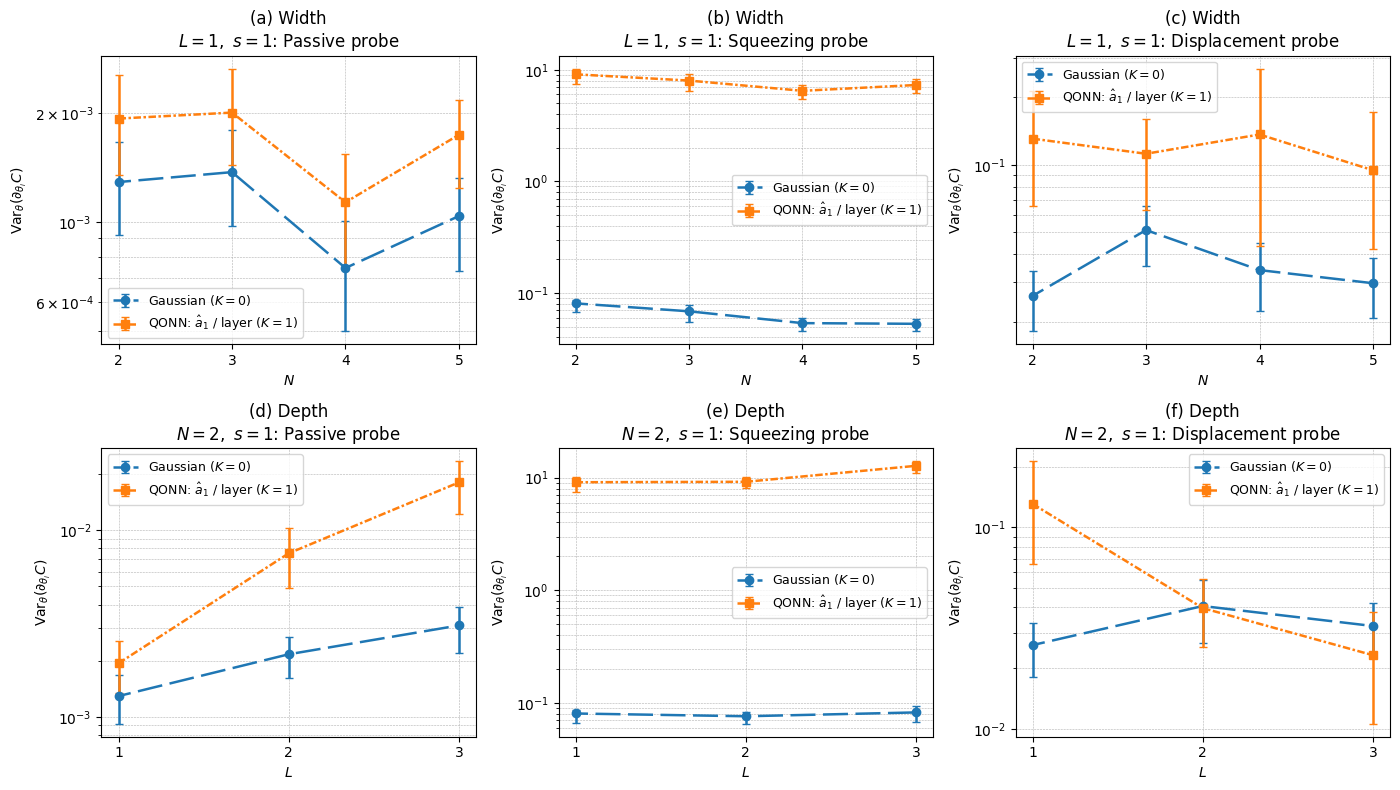

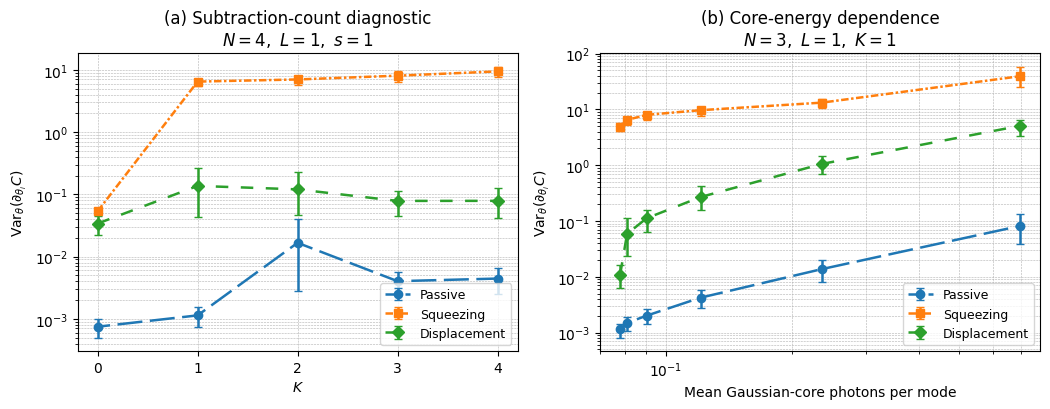

In [3]:
from quannto.tasks.revision.trainability import (
    _plot_gradient_variance, _plot_nongaussian_and_energy)
from quannto.utils.path_utils import figures_dir

rows_to_plot = metrics.to_dict("records")
output_directory = figures_dir()
_plot_gradient_variance(rows_to_plot, output_directory, show=True)
_plot_nongaussian_and_energy(rows_to_plot, output_directory, show=True)


**Interpretation.** Over the tested widths and depths, the squeezing probe has substantially larger variance after subtraction, while the displacement probe weakens with depth. The response to additional subtractions is not monotonic for every probe; increasing initialization energy raises all three probe variances. These are finite-size observations for this cost and ensemble.

## Physical controls

Compare the photon number per mode in the Gaussian core and the mean subtraction denominator across the sweeps. This denominator is the ideal branch norm used to normalize the conditional output; an experimental heralding probability also depends on the tap and detector model.

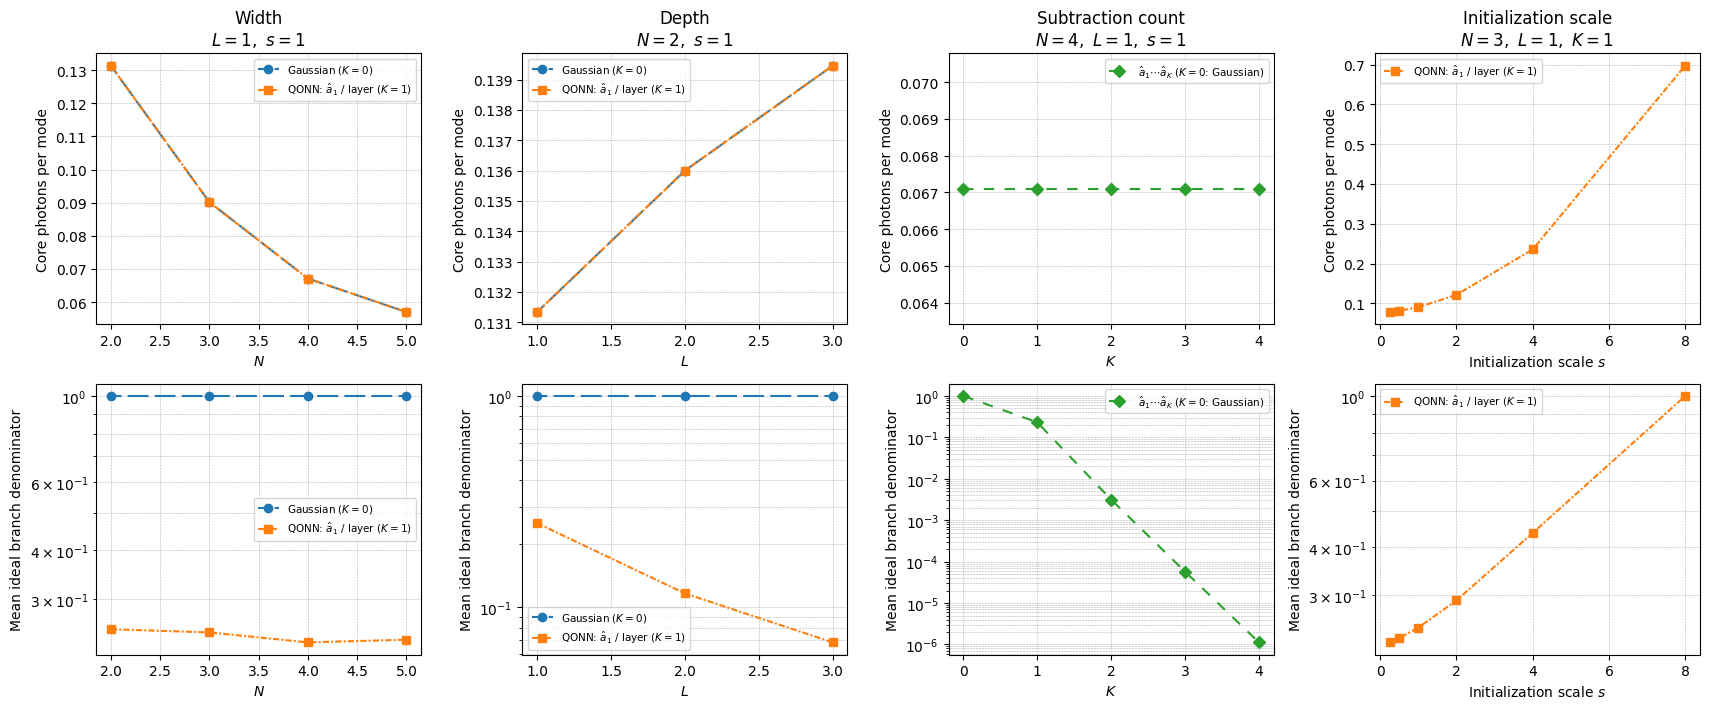

In [4]:
from quannto.tasks.revision.trainability import _plot_physical_controls

_plot_physical_controls(rows_to_plot, output_directory, show=True)

**Interpretation.** At fixed Gaussian-core energy, the branch denominator falls from 1 to about $10^{-6}$ as $K$ increases from 0 to 4. It also decreases with depth, whereas increasing the initialization scale raises both the core energy and denominator. Large conditional gradients therefore need to be read alongside the branch-weight diagnostics.

## Parameter families

Compare the median gradient variance for passive-optics, squeezing and displacement parameters. Separating these families helps identify which controls carry the gradient signal.

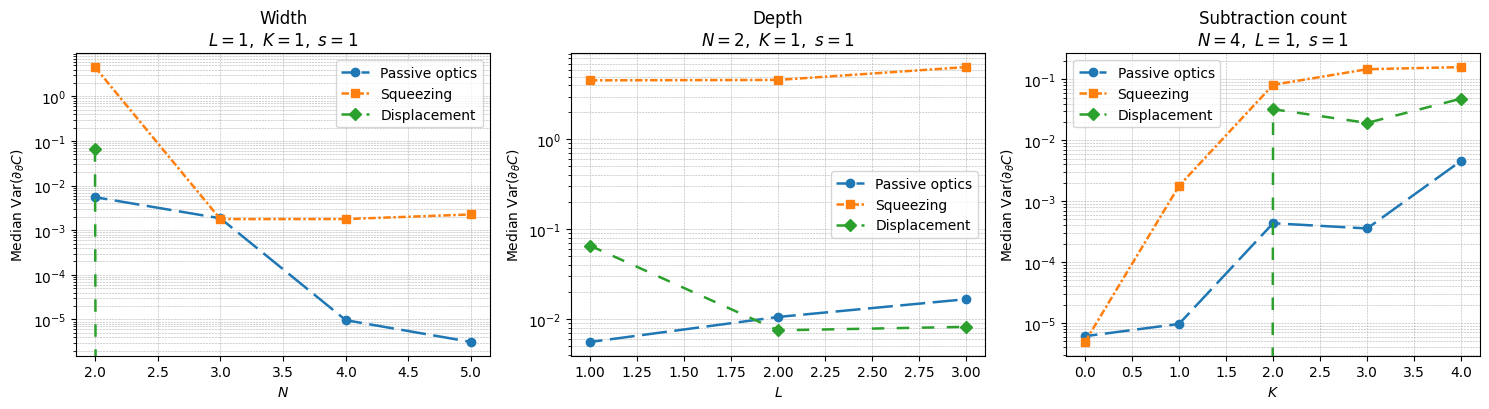

In [5]:
from quannto.tasks.revision.trainability import _plot_parameter_families

_plot_parameter_families(rows_to_plot, output_directory, show=True)

**Interpretation.** Parameter families behave differently: passive-coordinate medians decrease with width, and displacement medians can be zero even when the selected displacement probe remains active. A family median can therefore hide a small set of active coordinates; it is not interchangeable with an individual-derivative variance.

## Gradient norms and inactive coordinates

Compare the total gradient norm and the fraction of parameter coordinates with negligible gradients under the recorded tolerance. These aggregate diagnostics complement the individual-derivative variance plots. A coordinate is counted as inactive when its absolute gradient is at most $10^{-12}$ in all 64 initializations.

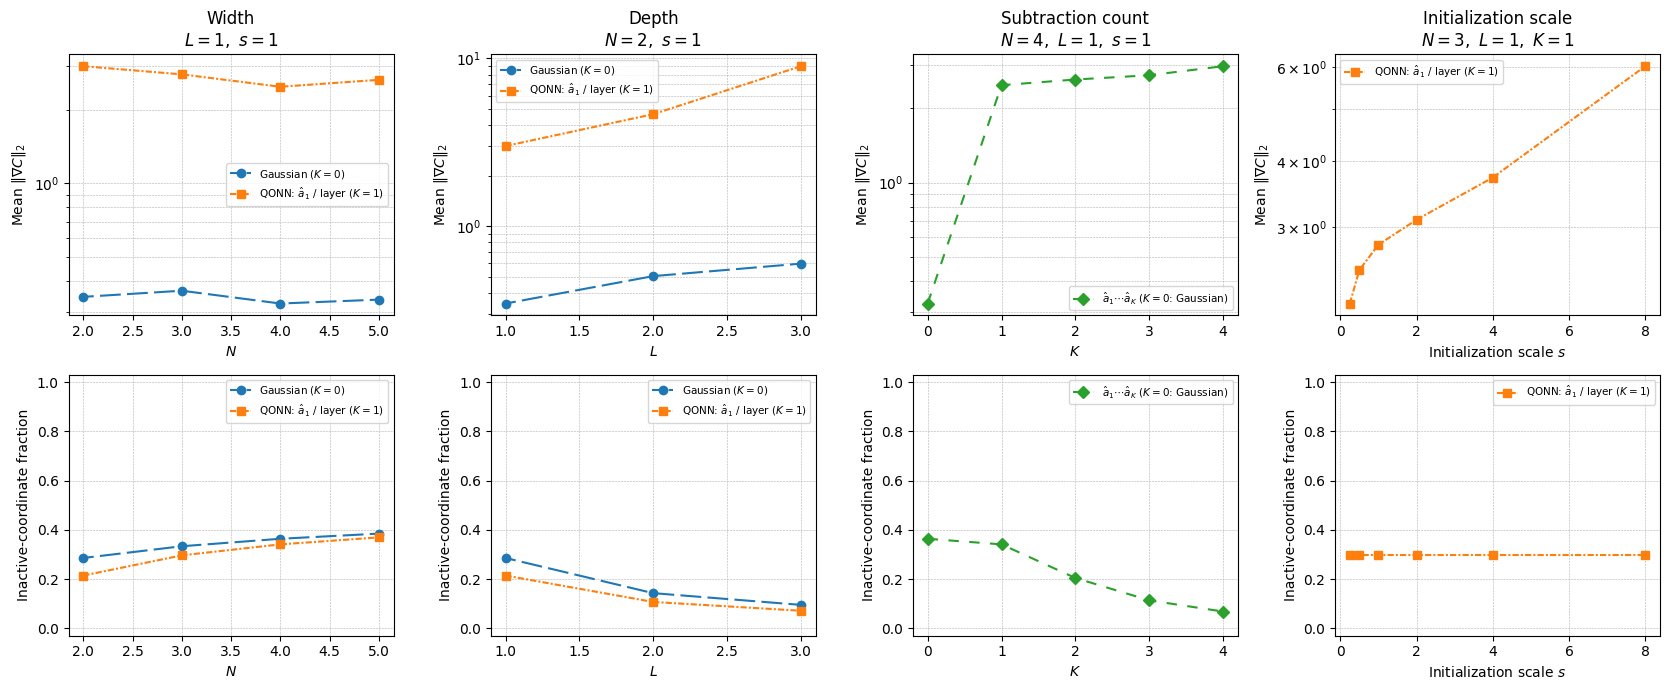

In [6]:
from quannto.tasks.revision.trainability import _plot_aggregate_diagnostics

_plot_aggregate_diagnostics(rows_to_plot, output_directory, show=True)

**Interpretation.** Subtracted models have larger total gradient norms than Gaussian controls here. The inactive-coordinate fraction rises with width but falls with depth and subtraction count. Since the number of parameters also changes, the total norm alone does not describe how well each coordinate is conditioned.